# Classificador de Temática de IA (v0) — EDA + baseline

**Projeto:** Impacto das fake news geradas por IA no eleitor brasileiro — Fase 3 (`/models`).

Este notebook documenta, de forma exploratória e reprodutível, a construção do
baseline v0 descrito em `models/README.md` e `docs/PRD.md` (Seção 4.1): um
classificador que estima se um texto político é **sobre** desinformação
envolvendo IA (deepfake, áudio clonado, texto sintético) — não um detector de
**autoria** por IA (essa é uma tarefa diferente, roadmapeada para v1, que
exige dados que ainda não existem neste repositório).

O treino "de produção" (que gera o artefato usado pela API em `models/api/main.py`)
roda via `python -m models_pkg.training.train_ia_topic_classifier` — este
notebook re-executa o mesmo pipeline célula a célula, para inspecionar cada
etapa (incluindo o confound de desenho amostral encontrado nos dados).


In [1]:

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

sys.path.insert(0, str(Path("../src").resolve()))

from models_pkg.data.loader import load_dataset_b_enriquecido, build_text_field, stratified_split
from models_pkg.features.text_features import build_tfidf_vectorizer
from models_pkg.evaluation.metrics import compute_classification_metrics
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 90)

SEED = 42


## 1. Carga dos dados (Dataset B enriquecido — única fonte com rótulo editorial real de IA)

In [2]:

df = load_dataset_b_enriquecido("../../data/processed/dataset_b_aosfatos_enriquecido.csv")
print(f"{len(df)} itens, {len(df.columns)} colunas")
df["rotulo_grupo"].value_counts()


553 itens, 16 colunas


rotulo_grupo
Tradicional    431
IA             122
Name: count, dtype: int64

### Por que só o Dataset B

O Dataset A tem uma coluna `rotulo_ia`, mas ela vem de uma heurística de regex
sobre o título (`fonte_rotulo_ia == "heuristica_regex_titulo"`), não de
julgamento editorial — e, na coleta atual, nunca marca nenhum item como IA
(0/322). Incluí-lo infllaria a classe "Tradicional" com um rótulo de
qualidade diferente do rótulo real do Dataset B. Ver
`models/src/models_pkg/data/loader.py` para a discussão completa.


## 2. Confound de desenho amostral: o rótulo é colinear com a tag de busca

In [3]:

crosstab = pd.crosstab(df["tag_pesquisa"], df["rotulo_grupo"])
crosstab


rotulo_grupo,IA,Tradicional
tag_pesquisa,,
eleicoes-2022,0,419
eleicoes-2026,0,12
inteligencia-artificial,122,0


**Achado (que precisa ser lido antes de interpretar qualquer métrica abaixo):**
100% dos itens rotulados "IA" vêm da busca `inteligencia-artificial`; nenhum
item de `eleicoes-2022`/`eleicoes-2026` foi rotulado IA. Isso é consistente
com o rótulo refletir o tema real dos textos, mas significa que o
classificador pode estar aprendendo, em parte, diferenças de lote/época de
coleta — não só de tema. Ver `models/README.md`, "Limitações", item 1.


## 3. Tamanho do texto por grupo (checagem rápida de vazamento trivial por comprimento)

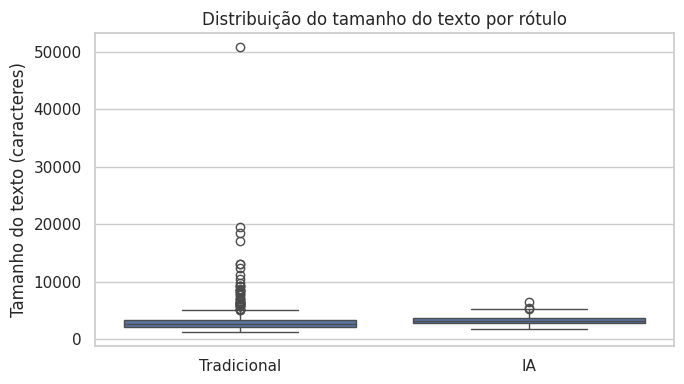

,count,mean,std,min,25%,50%,75%,max
rotulo_grupo,,,,,,,,
IA,122.0,3306.713115,781.311966,1758.0,2760.75,3161.5,3730.25,6424.0
Tradicional,431.0,3289.078886,3132.905240,1299.0,2130.50,2599.0,3325.50,50805.0


In [4]:

texto_completo = build_text_field(df, ["titulo", "corpo_artigo"])
tamanhos = texto_completo.str.len()

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(x=df["rotulo_grupo"], y=tamanhos, ax=ax, order=["Tradicional", "IA"])
ax.set_ylabel("Tamanho do texto (caracteres)")
ax.set_xlabel("")
ax.set_title("Distribuição do tamanho do texto por rótulo")
plt.tight_layout(); plt.show()

tamanhos.groupby(df["rotulo_grupo"]).describe()


## 4. Split estratificado e vetorização TF-IDF

In [5]:

split = stratified_split(
    df,
    text_columns=["titulo", "corpo_artigo"],
    label_column="rotulo_grupo",
    positive_label="IA",
    test_size=0.2,
    val_size=0.1,
    seed=SEED,
)
print(f"Treino: {len(split.X_train)} | Validação: {len(split.X_val)} | Teste: {len(split.X_test)}")
print(f"Proporção IA — treino: {split.y_train.mean():.3f}, val: {split.y_val.mean():.3f}, teste: {split.y_test.mean():.3f}")


Treino: 397 | Validação: 45 | Teste: 111
Proporção IA — treino: 0.222, val: 0.222, teste: 0.216


## 5. Treino do baseline (regressão logística sobre TF-IDF)

In [6]:

vectorizer = build_tfidf_vectorizer(max_features=8000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
clf = LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000, random_state=SEED)
pipeline = Pipeline([("tfidf", vectorizer), ("clf", clf)])

X_fit = pd.concat([split.X_train, split.X_val])
y_fit = pd.concat([split.y_train, split.y_val])
pipeline.fit(X_fit, y_fit)

y_pred = pipeline.predict(split.X_test)
y_proba = pipeline.predict_proba(split.X_test)[:, 1]

metrics = compute_classification_metrics(split.y_test.to_numpy(), y_pred, y_proba)
metrics


{'acuracia': 0.990990990990991,
 'roc_auc': 1.0,
 'por_classe': {'Tradicional': {'precisao': 1.0,
   'recall': 0.9885057471264368,
   'f1': 0.9942196531791907,
   'n': 87},
  'IA': {'precisao': 0.96, 'recall': 1.0, 'f1': 0.9795918367346939, 'n': 24}},
 'matriz_confusao': {'labels': ['Tradicional', 'IA'],
  'valores': [[86, 1], [0, 24]],
  'nota': 'linhas = rótulo real, colunas = predição'}}

## 6. Matriz de confusão

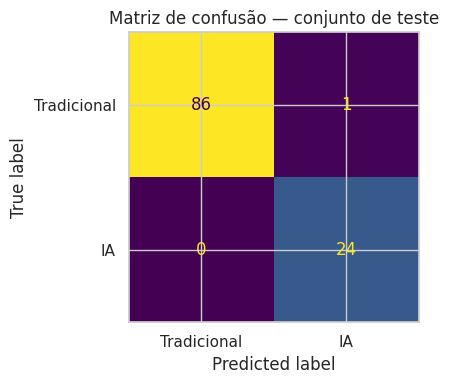

In [7]:

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    split.y_test, y_pred, display_labels=["Tradicional", "IA"], ax=ax, colorbar=False
)
ax.set_title("Matriz de confusão — conjunto de teste")
plt.tight_layout(); plt.show()


## 7. Termos mais associados a cada classe (coeficientes do modelo linear)

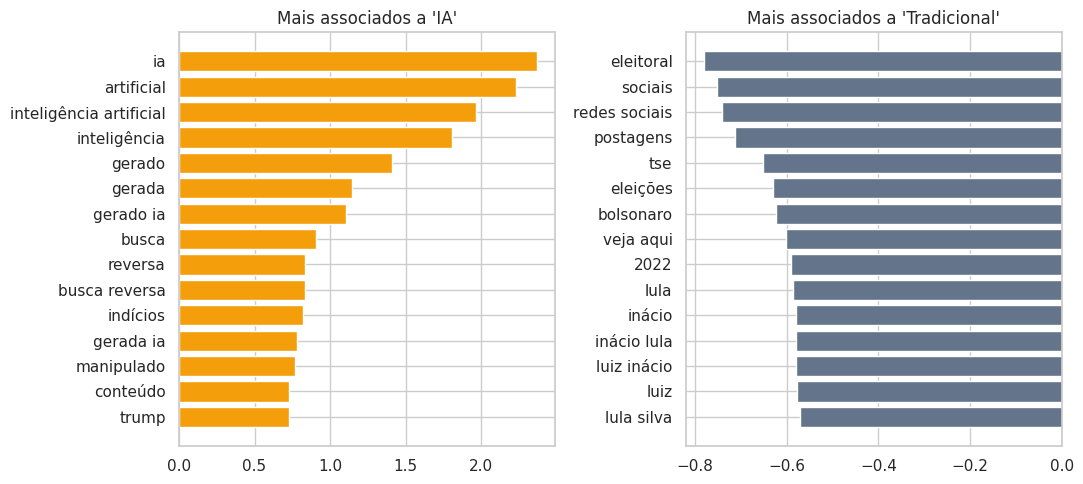

In [8]:

termos = np.array(vectorizer.get_feature_names_out())
coefs = clf.coef_[0]

top_ia = np.argsort(coefs)[-15:][::-1]
top_trad = np.argsort(coefs)[:15]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].barh(termos[top_ia][::-1], coefs[top_ia][::-1], color="#f59e0b")
axes[0].set_title("Mais associados a 'IA'")
axes[1].barh(termos[top_trad][::-1], coefs[top_trad][::-1], color="#64748b")
axes[1].set_title("Mais associados a 'Tradicional'")
plt.tight_layout(); plt.show()


## 8. Exemplos de predição em texto livre (fora do dataset de treino)

In [9]:

exemplos = [
    "Um vídeo manipulado por inteligência artificial mostra o candidato fazendo declarações que ele nunca fez.",
    "O TSE informou que as urnas eletrônicas passaram por testes de integridade antes do primeiro turno.",
    "Áudio clonado por IA circula em grupos de WhatsApp atribuindo falas falsas a uma autoridade eleitoral.",
    "Pesquisa de intenção de voto mostra empate técnico entre os dois principais candidatos.",
]

for texto in exemplos:
    proba = pipeline.predict_proba([texto])[0, 1]
    rotulo = "IA" if proba >= 0.5 else "Tradicional"
    print(f"[{rotulo} | p(IA)={proba:.2f}] {texto}")


[IA | p(IA)=0.74] Um vídeo manipulado por inteligência artificial mostra o candidato fazendo declarações que ele nunca fez.
[Tradicional | p(IA)=0.20] O TSE informou que as urnas eletrônicas passaram por testes de integridade antes do primeiro turno.
[Tradicional | p(IA)=0.45] Áudio clonado por IA circula em grupos de WhatsApp atribuindo falas falsas a uma autoridade eleitoral.
[Tradicional | p(IA)=0.30] Pesquisa de intenção de voto mostra empate técnico entre os dois principais candidatos.


## 9. Limitações (resumo — ver `models/README.md` para a versão completa)

1. **Confound de desenho amostral**: o rótulo IA é perfeitamente colinear com
   a tag de busca usada na coleta — ver Seção 2. As métricas acima podem
   incluir sinais de lote/época de coleta, não só de tema.
2. **Amostra pequena**: 122 itens IA no total. Qualquer diferença deve ser
   lida como indicativa, não como estatisticamente robusta para decisões de
   alto risco.
3. **Temática ≠ autoria**: este classificador não detecta se um texto foi
   escrito por IA — só se ele é sobre o tema "IA na política". Um detector
   de autoria (v1) exige um corpus pareado texto-humano vs.
   texto-gerado-por-IA que ainda não existe neste repositório (ver
   `docs/PRD.md`, Seção 4.3).
4. **Sem tuning de hiperparâmetros nesta v0**: o conjunto de validação foi
   usado apenas para compor o treino final (junto com o treino), não para
   busca de hiperparâmetros — fica para uma v0.1.

O artefato "de produção" (usado pela API em `models/api/main.py`) é gerado
por `python -m models_pkg.training.train_ia_topic_classifier`, que roda
exatamente este pipeline e adicionalmente salva o modelo (`artifacts/*.joblib`),
as métricas (`artifacts/*_metrics.json`) e um model card
(`artifacts/*_model_card.md`).
